<a href="https://colab.research.google.com/github/adityarizqiqa/PCVK_Ganjil2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama : Aditya Rizqiqa Ramadhan
NIM  : 244107020008
Kelas : TI-3E

In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Import seluruh library yang dibutuhkan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans

Mounted at /content/drive


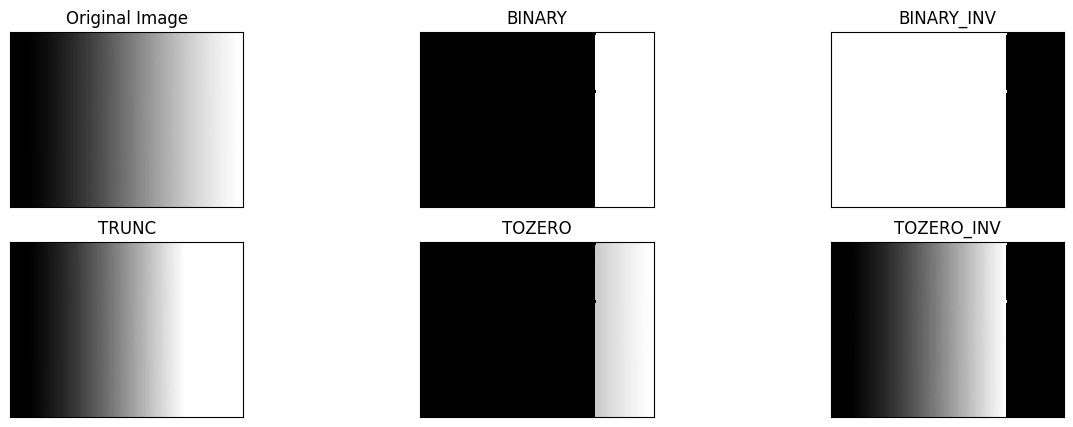

In [ ]:
# 3. Global Threshold secara Manual (Threshold = 200)
filename_grad = '/content/drive/MyDrive/PCVK/gradient.jpg'
img_grad = cv.imread(filename_grad, 0)
thresh = 200
maxval = 255

thresh1 = np.where(img_grad > thresh, maxval, 0).astype(np.uint8)          # BINARY
thresh2 = np.where(img_grad > thresh, 0, maxval).astype(np.uint8)          # BINARY_INV
thresh3 = np.where(img_grad > thresh, thresh, img_grad).astype(np.uint8)   # TRUNC
thresh4 = np.where(img_grad > thresh, img_grad, 0).astype(np.uint8)        # TOZERO
thresh5 = np.where(img_grad > thresh, 0, img_grad).astype(np.uint8)        # TOZERO_INV

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img_grad, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

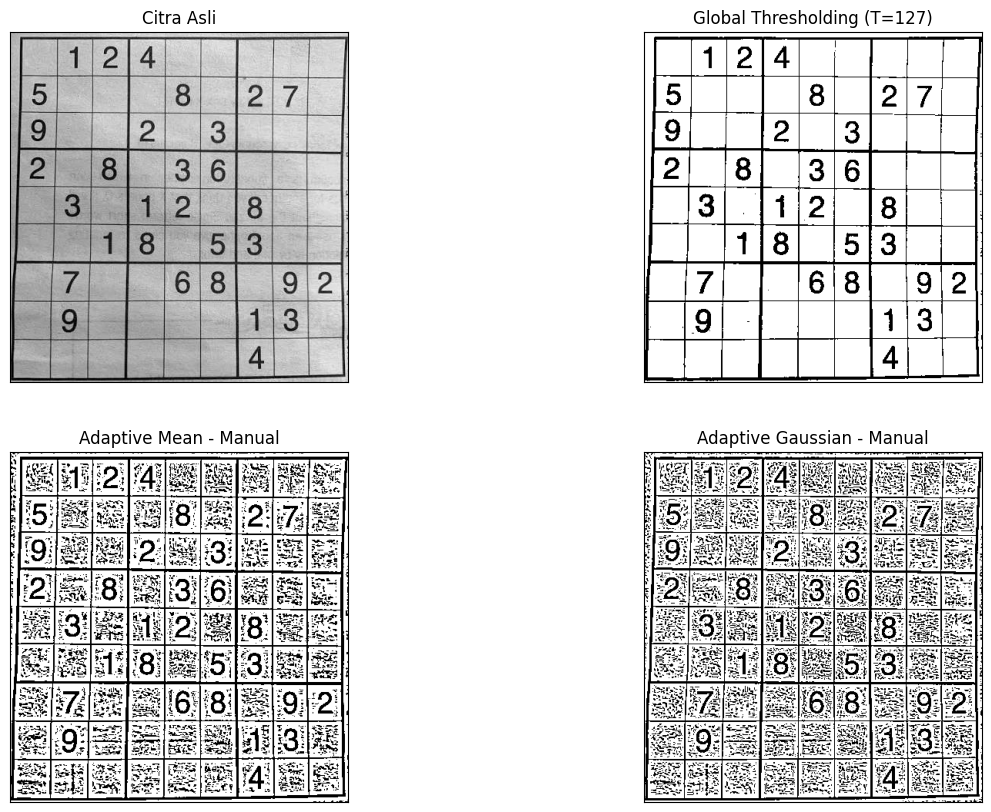

In [ ]:
# 4. Adaptive Threshold secara manual (Tanpa cv.adaptiveThreshold)
filename_sudoku = '/content/drive/MyDrive/PCVK/sudoku.jpg'
img_sudoku = cv.imread(filename_sudoku, 0)

# Global Thresholding Manual (v=127)
global_thresh = np.where(img_sudoku > 127, 255, 0).astype(np.uint8)

# Fungsi untuk Adaptive Mean Thresholding
def adaptive_mean_manual(img, window_size=11, C=2):
    pad = window_size // 2
    padded_img = np.pad(img, pad, mode='reflect')
    res = np.zeros_like(img)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            window = padded_img[i:i+window_size, j:j+window_size]
            mean_val = np.mean(window)
            if img[i, j] > (mean_val - C):
                res[i, j] = 255
            else:
                res[i, j] = 0
    return res

# Fungsi untuk membuat Gaussian kernel manual
def gaussian_kernel(size, sigma=2):
    kernel = np.zeros((size, size))
    center = size // 2
    for i in range(size):
        for j in range(size):
            x, y = i - center, j - center
            kernel[i, j] = (1 / (2 * np.pi * sigma**2)) * np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / np.sum(kernel)

# Fungsi untuk Adaptive Gaussian Thresholding
def adaptive_gaussian_manual(img, window_size=11, C=2, sigma=2):
    pad = window_size // 2
    padded_img = np.pad(img, pad, mode='reflect')
    res = np.zeros_like(img)
    kernel = gaussian_kernel(window_size, sigma)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            window = padded_img[i:i+window_size, j:j+window_size]
            weighted_mean = np.sum(window * kernel)
            if img[i, j] > (weighted_mean - C):
                res[i, j] = 255
            else:
                res[i, j] = 0
    return res

adp_mean = adaptive_mean_manual(img_sudoku)
adp_gauss = adaptive_gaussian_manual(img_sudoku)

titles = ['Citra Asli', 'Global Thresholding (T=127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [img_sudoku, global_thresh, adp_mean, adp_gauss]

plt.figure(figsize=(15, 10))
for i in range(len(images)):
    plt.subplot(2, 2, i+1), plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

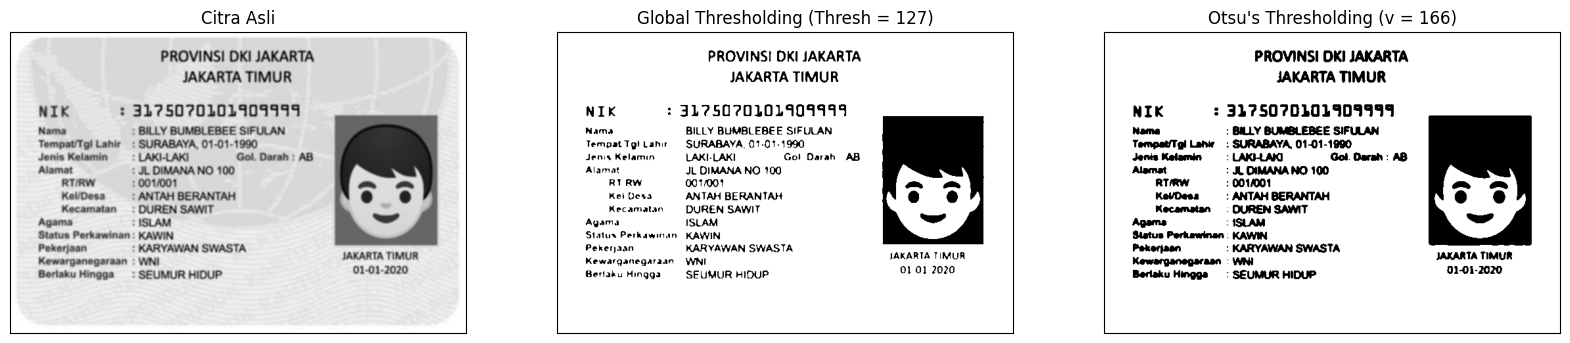

In [ ]:
# 5A. Otsu's Thresholding tanpa menggunakan Library
filename_lena = '/content/drive/MyDrive/PCVK/ktp_fulan.jpg'
img_lena = cv.imread(filename_lena, 0)
blur = cv.GaussianBlur(img_lena, (5,5), 0)
thresh_val = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0: continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)

        value = Wb * Wf * (mub - muf)**2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
ret, th1 = cv.threshold(blur, thresh_val, 255, cv.THRESH_BINARY)
title_otsu = f"Otsu's Thresholding (v = {otsu_thresh})"
titles = ['Citra Asli', f'Global Thresholding (Thresh = {thresh_val})', title_otsu]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()


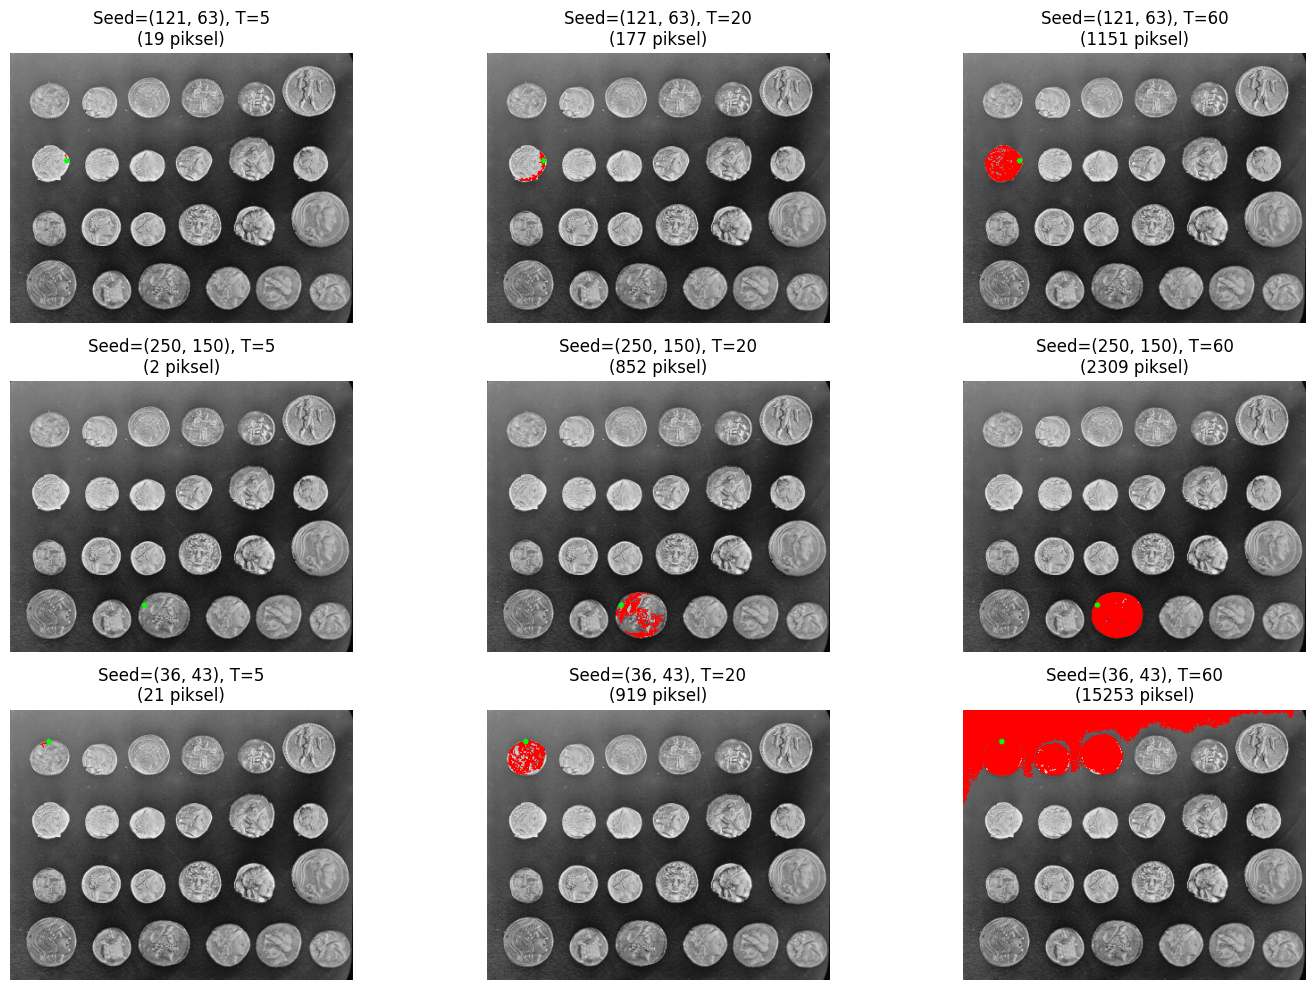

In [ ]:
# 6. Segmentasi Berbasis Region menggunakan skimage
gray_coins = data.coins()

seeds = [(121, 63), (250, 150), (36, 43)]
tolerances = [5, 20, 60]

plt.figure(figsize=(15, 10))
plot_idx = 1
for seed in seeds:
    for t in tolerances:
        # Segmentasi flood
        region = flood(gray_coins, seed_point=seed, tolerance=t, connectivity=1)

        # Pewarnaan untuk visualisasi
        res_colored = cv.cvtColor(gray_coins.copy(), cv.COLOR_GRAY2BGR)
        res_colored[region] = [255, 0, 0] # Highlight region jadi biru/merah
        cv.circle(res_colored, (seed[1], seed[0]), 3, (0, 255, 0), -1) # Titik seed hijau

        plt.subplot(3, 3, plot_idx)
        plt.imshow(res_colored)
        plt.title(f"Seed={seed}, T={t}\n({np.sum(region)} piksel)")
        plt.axis('off')
        plot_idx += 1

plt.tight_layout()
plt.show()

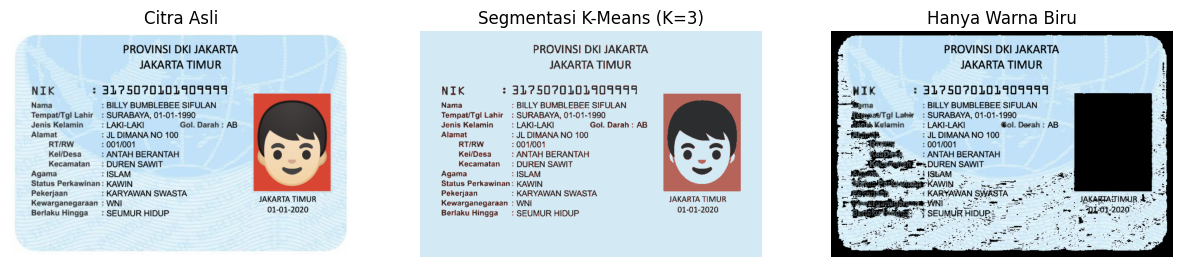

In [ ]:
# 7. Segmentasi Warna Biru pada image ktp_fulan.jpg
filename_ktp = '/content/drive/MyDrive/PCVK/ktp_fulan.jpg'
img_ktp = cv.imread(filename_ktp)
img_rgb = cv.cvtColor(img_ktp, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img_ktp, cv.COLOR_BGR2HSV)

# Masking berbasis Rentang HSV untuk mencari latar belakang Biru
# Rentang Hue (Biru Muda/Tua) dari soal: (H>=85) & (H<=130) & (S>=25) & (V>=40)
lower_blue = np.array([85, 25, 40])
upper_blue = np.array([130, 255, 255])
mask = cv.inRange(img_hsv, lower_blue, upper_blue)

# Menerapkan Mask
only_blue = cv.bitwise_and(img_rgb, img_rgb, mask=mask)

# Menerapkan K-Means clustering sebagai pelengkap (K=3)
Z = np.float32(img_rgb.reshape((-1, 3)))
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(Z)
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented_kmeans = centers[labels.flatten()].reshape(img_rgb.shape)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img_rgb)
ax[0].set_title('Citra Asli')
ax[0].axis('off')

ax[1].imshow(segmented_kmeans)
ax[1].set_title('Segmentasi K-Means (K=3)')
ax[1].axis('off')

ax[2].imshow(only_blue)
ax[2].set_title('Hanya Warna Biru')
ax[2].axis('off')
plt.show()

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...



--- Teks Terbaca pada Citra Asli ---
PROVINSI DKI JAKARTA JAKARTA TIMUR NIK 1 Nama : BILLY BUMBLEBEE SIFULAN Tempat/Tgl Lahir SURABAYA, 01-01-1990 Jenis LAKI-LAKI Gol. Darah : AB Alamat : JL DIMANA NO 100 RTIRW ANTAH BERANTAH N 4 DUREN SAWIT Agama : ISLAM Status Perkawinan : KAWIN Pekerjaan : KARYAWAN SWASTA Kewarganegaraan : WNI Berlaku Hingga : SEUMUR HIDUP 01-01-2020

--- Teks Terbaca pada Otsu ---
PROVINSI DKI JAKARTA JAKARTA TIMUR NIK 1 Nama : BILLY BUMBLEBEE SIFULAN Lahir : SURABAYA, 01-01-1990 Jenis LAKI-LAKI Gol. Darah : AB Alamat : JL DIMANA NO 100 RTIRW :001/001 ANTAH BERANTAH DUREN SAWIT Agama : ISLAM Status Perkawinan: KAWIN Pekerjaan : KARYAWAN SWASTA Kewarganegaraan : WNI JAKARTA TIMUR Berlaku SEUMUR HIDUP 01-01-2020

--- Teks Terbaca pada Adaptive ---
3 PROVINSI DKI JAKARTA TIMUR | NIK BILLY BUMBLEBEE SIFULAN SURABAYA, Jenis Kelamin LAKI-LAKI Darah Alamat DIMANA NO j ANTAH Oo, o) 15 DUREN KAWIN Kewarganegaraan


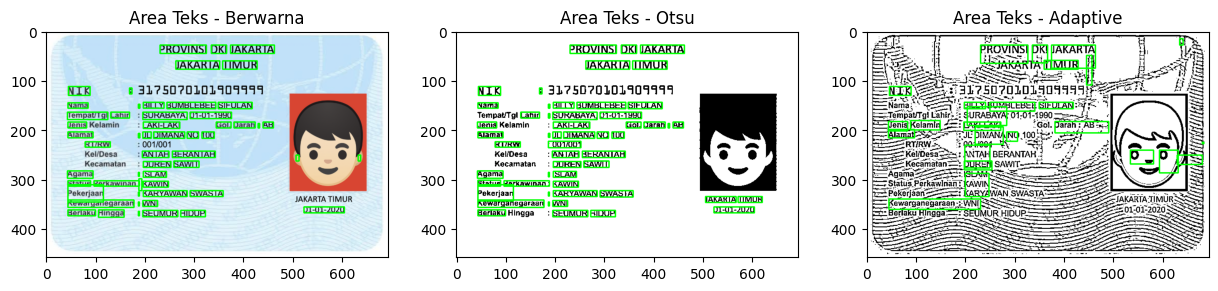

In [ ]:
import pytesseract
from pytesseract import Output

gray_ktp = cv.cvtColor(img_ktp, cv.COLOR_BGR2GRAY)
img_ori = img_rgb.copy()

ret, img_otsu = cv.threshold(gray_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adapt = cv.adaptiveThreshold(gray_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

custom_config = r'-l ind --psm 6'

def process_ocr(image_input, title):
    img_copy = image_input.copy()
    if len(img_copy.shape) == 2:
        img_copy = cv.cvtColor(img_copy, cv.COLOR_GRAY2RGB)

    d = pytesseract.image_to_data(image_input, config=custom_config, output_type=Output.DICT)

    text_result = []
    for i in range(len(d['text'])):
        if int(d['conf'][i]) > 60: # Batas Confidence
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
            cv.rectangle(img_copy, (x, y), (x + w, y + h), (0, 255, 0), 2)
            text_result.append(d['text'][i])

    print(f"\n--- Teks Terbaca pada {title} ---")
    print(" ".join(text_result))
    return img_copy

box_ori = process_ocr(img_rgb, "Citra Asli")
box_otsu = process_ocr(img_otsu, "Otsu")
box_adapt = process_ocr(img_adapt, "Adaptive")

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(box_ori), plt.title("Area Teks - Berwarna")
plt.subplot(132), plt.imshow(box_otsu), plt.title("Area Teks - Otsu")
plt.subplot(133), plt.imshow(box_adapt), plt.title("Area Teks - Adaptive")
plt.show()